## 1. Robust Multi-Partition Sample Discovery Across Extracted Shard Folders
* **Directory Traversal:** Recursively navigates all attached partition folders (`gamus-pretiles-*`) and discovers uncompressed shard directories (`train-*`, `val-*`, `test-*`).
* **Sample Key Aggregation:** Identifies individual crops by locating `.rgb.png` files, ignoring system artifacts (`.virtual_documents`, `.ipynb_checkpoints`).
* **Metadata Indexing:** Indexes the path stem for every sample so the dataset can fetch associated `.height.npy`, `.valid.png`, and `.json` files without opening tar archives.

In [1]:
import os
import json
from pathlib import Path
from collections import defaultdict

BASE_ROOT = Path("/kaggle/input/datasets")
SPLITS = ("train", "val", "test")

sample_records = defaultdict(list)
partition_audit = defaultdict(lambda: defaultdict(int))

user_dirs = [
    Path(e.path) for e in os.scandir(BASE_ROOT)
    if e.is_dir() and not e.name.startswith(".")
]


dataset_dirs = []
for u_dir in user_dirs:
    for e in os.scandir(u_dir):
        if e.is_dir() and not e.name.startswith("."):
            dataset_dirs.append(Path(e.path))


# 2. Direct path resolution for partition reports (no recursive crawling)
for d in sorted(dataset_dirs):
    print(f"  - {d}")

# 2. Targeted search for partition-report.json in each dataset folder
report_paths = []
for ds_root in dataset_dirs:
    # Direct candidate checks (handles flat or 1-level nested Kaggle output)
    candidates = [
        ds_root / "partition-report.json",
        ds_root / ds_root.name / "partition-report.json",
    ]
    for p in candidates:
        if p.is_file():
            report_paths.append(p)
            break

print(f"\nDirectly located {len(report_paths)} report file(s):")
for p in report_paths:
    print(f"  - {p}")

assert len(report_paths) == 6, (
    f"Expected 6 partition reports, but located {len(report_paths)}. "
    "Verify that all user partition datasets are attached."
)

# 3. Read metadata and index samples from specific shard folders only
for report_path in report_paths:
    partition_root = report_path.parent
    report = json.loads(report_path.read_text())
    part_id = report.get("partition_id", partition_root.name)
    partition_key = f"partition-{part_id:02d}" if isinstance(part_id, int) else str(part_id)

    for shard in report.get("shards", []):
        split = shard["split"]
        shard_tar_name = Path(shard["path"]).name
        shard_folder = shard_tar_name.replace(".tar", "")

        # Check standard Kaggle extraction path: partition_root / split / shard_folder
        target_dir = partition_root / split / shard_folder
        if not target_dir.is_dir():
            target_dir = partition_root / split

        if not target_dir.is_dir():
            continue

        # Fast non-recursive scan of the shard folder
        with os.scandir(target_dir) as entries:
            for entry in entries:
                if entry.name.endswith(".rgb.png") and not entry.name.startswith("."):
                    base_prefix = str(target_dir / entry.name[:-8])
                    sample_records[split].append(base_prefix)
                    partition_audit[partition_key][split] += 1

print("\n--- Instant Discovery Summary ---")
for split in SPLITS:
    print(f"Total {split.upper()} samples indexed: {len(sample_records[split])}")

print("\n--- Per-Partition Breakdown ---")
for part, counts in sorted(partition_audit.items()):
    counts_str = ", ".join(f"{s}: {counts[s]}" for s in SPLITS)
    print(f"  {part} -> {counts_str}")

  - /kaggle/input/datasets/aritracoder/gamus-pretiles-03
  - /kaggle/input/datasets/aritracoder/gamus-pretiles-05
  - /kaggle/input/datasets/avishiktahajra/gamus-pretiles-04
  - /kaggle/input/datasets/avishiktahajra/gamus-pretiles-06
  - /kaggle/input/datasets/boxedinthecube/gamus-pretiles-01
  - /kaggle/input/datasets/boxedinthecube/gamus-pretiles-02

Directly located 6 report file(s):
  - /kaggle/input/datasets/avishiktahajra/gamus-pretiles-04/gamus-pretiles-04/partition-report.json
  - /kaggle/input/datasets/avishiktahajra/gamus-pretiles-06/gamus-pretiles-06/partition-report.json
  - /kaggle/input/datasets/aritracoder/gamus-pretiles-05/gamus-pretiles-05/partition-report.json
  - /kaggle/input/datasets/aritracoder/gamus-pretiles-03/gamus-pretiles-03/partition-report.json
  - /kaggle/input/datasets/boxedinthecube/gamus-pretiles-02/gamus-pretiles-02/partition-report.json
  - /kaggle/input/datasets/boxedinthecube/gamus-pretiles-01/gamus-pretiles-01/partition-report.json

--- Instant Dis

## 2. Standalone PyTorch GAMUS Dataset Definition
* **Direct Disk I/O:** Loads images via PIL and height matrices via `np.load` directly from the filesystem.
* **Tensor Formatting:** Converts RGB crops to `[3, 518, 518]` float tensors and height maps to `[1, 518, 518]`.
* **Safety Clamping:** Clamps ground-truth height maps to $\ge 0.0$ to ensure zero and sub-zero LiDAR values do not cause `NaN` errors in log scale-invariant loss calculations.

In [2]:
import os
import json
import numpy as np
import torch
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from PIL import Image

class GamusDiskDataset(Dataset):
    def __init__(self, sample_prefixes):
        self.sample_prefixes = sample_prefixes

    def __len__(self):
        return len(self.sample_prefixes)

    def __getitem__(self, idx):
        prefix = self.sample_prefixes[idx]
        
        # 1. Load RGB
        rgb_path = f"{prefix}.rgb.png"
        rgb = np.array(Image.open(rgb_path).convert("RGB"))
        rgb_tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0
        
        # 2. Load Height (nDSM in metres)
        height_path = f"{prefix}.height.npy"
        height = np.load(height_path).astype(np.float32)
        height_tensor = torch.from_numpy(height).unsqueeze(0)
        
        # 3. Load Valid Mask
        valid_path = f"{prefix}.valid.png"
        if os.path.exists(valid_path):
            valid_mask = np.array(Image.open(valid_path).convert("L"))
            valid_tensor = torch.from_numpy(valid_mask).unsqueeze(0) > 127
        else:
            valid_tensor = torch.ones_like(height_tensor, dtype=torch.bool)

        # 4. Load Metadata
        json_path = f"{prefix}.json"
        meta = {}
        if os.path.exists(json_path):
            with open(json_path, 'r') as f:
                meta = json.load(f)

        # --- CONTRACT UPDATE: Preserve negative labels, ignore exact -5.0 ---
        # Mask rule: finite and not exact -5
        valid_tensor = valid_tensor & torch.isfinite(height_tensor) & (height_tensor != -5.0)
        
        # Replace invalid pixels with 0.0 so they don't contribute to loss, 
        # but DO NOT clamp valid negative heights.
        height_tensor[~valid_tensor] = 0.0 

        return {
            "rgb": rgb_tensor,
            "height": height_tensor,
            "valid_mask": valid_tensor,
            "meta": meta,
        }

## 3. DataLoader Construction
* **Multi-Worker Execution:** Initializes standard PyTorch `DataLoader` instances with background multiprocessing (`num_workers=2`).
* **Batch Sizing:** Configures micro-batches of size 1 with pinned memory, matching the target VRAM budget on Kaggle T4/P100 GPUs.

In [3]:
from torch.utils.data import DataLoader

assert len(sample_records["train"]) > 0, "No train samples found. Check folder discovery."
assert len(sample_records["val"]) > 0, "No val samples found. Check folder discovery."

# Subsample: Take every 4th crop (25% stratified subset ~ 5,000 crops across DC, NYC, PHL)
# This cuts training iterations by 75% while keeping geographic balance intact
train_subset_prefixes = sample_records["train"][::2]
val_subset_prefixes = sample_records["val"][::2]

train_dataset = GamusDiskDataset(train_subset_prefixes)
val_dataset = GamusDiskDataset(val_subset_prefixes)

# batch_size=2 lets PyTorch send 1 sample to GPU 0 and 1 sample to GPU 1 in parallel
# num_workers=4 prevents GPU starvation from disk I/O
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print(f"DataLoaders successfully built:")
print(f"  - Train steps per epoch: {len(train_loader)}")
print(f"  - Val steps per epoch:   {len(val_loader)}")

DataLoaders successfully built:
  - Train steps per epoch: 5004
  - Val steps per epoch:   1718


## 4. End-to-End Pipeline Smoke Test
* **Batch Verification:** Retrieves a micro-batch from `train_loader` to verify image loading, tensor conversion, and array shapes.
* **Range Check:** Confirms that height arrays and masks are non-negative and valid before training begins.

In [4]:
# Fetch one test batch from disk
sample_batch = next(iter(train_loader))

rgb = sample_batch["rgb"]
height = sample_batch["height"]
valid_mask = sample_batch["valid_mask"]

# Extract sample ID from metadata dict
meta_id = sample_batch["meta"]["sample_id"]
sample_id = meta_id[0] if isinstance(meta_id, list) else meta_id

print(f"Successfully loaded crop from disk: {sample_id}")
print(f"  RGB Tensor:        shape={tuple(rgb.shape)}, dtype={rgb.dtype}, range=[{rgb.min():.2f}, {rgb.max():.2f}]")
print(f"  Height Tensor:     shape={tuple(height.shape)}, dtype={height.dtype}, range=[{height.min():.2f}, {height.max():.2f}] m")
print(f"  Valid Mask Tensor: shape={tuple(valid_mask.shape)}, valid_pixels={int(valid_mask.sum().item())}/{valid_mask.numel()}")

Successfully loaded crop from disk: NYC_28008
  RGB Tensor:        shape=(2, 3, 518, 518), dtype=torch.float32, range=[0.00, 1.00]
  Height Tensor:     shape=(2, 1, 518, 518), dtype=torch.float32, range=[-0.25, 23.85] m
  Valid Mask Tensor: shape=(2, 1, 518, 518), valid_pixels=536648/536648


## 5. Architecture: DA-V2 Base Backbone, Residual Scale Adapters, and Decoders
* **Backbone Loading:** Loads the official Depth-Anything V2 Base ViT encoder and retains its pretrained DPT decoder blocks.
* **Residual Scale Adapters:** Attaches lightweight residual adapters to the 4 native intermediate ViT feature maps to adapt the model to nadir top-down remote-sensing cues without breaking geometric priors.
* **Multiscale & Uncertainty Heads:** Implements multiscale metric height prediction heads alongside an auxiliary log-variance uncertainty head.
* **Phase A Freezing:** Freezes the early two-thirds of the ViT encoder layers, updating only the adapters, DPT decoder, and new prediction heads.

In [5]:
import os
import sys
import subprocess
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

# - 1. Clone DA-V2 Repo & Download Official Base Weights (if missing) -
REPO_DIR = Path("/kaggle/working/Depth-Anything-V2")
WEIGHTS_PATH = REPO_DIR / "depth_anything_v2_vitb.pth"

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/DepthAnything/Depth-Anything-V2.git", str(REPO_DIR)], check=True)

if not WEIGHTS_PATH.exists():
    subprocess.run(["wget", "-q", "-O", str(WEIGHTS_PATH), "https://huggingface.co/depth-anything/Depth-Anything-V2-Base/resolve/main/depth_anything_v2_vitb.pth"], check=True)

sys.path.append(str(REPO_DIR))
from depth_anything_v2.dpt import DepthAnythingV2

# - 2. Custom Adapters & Metric Heads -
class ResidualScaleAdapter(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.adapter = nn.Sequential(
            nn.LayerNorm(dim, eps=1e-5),
            nn.Linear(dim, dim // 4),
            nn.GELU(),
            nn.Linear(dim // 4, dim),
        )
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

    def forward(self, x):
        if isinstance(x, tuple):
            tokens, cls_token = x
            tokens_f32 = tokens.clone().float()
            cls_clone = cls_token.clone() if cls_token is not None else None
            adapted = self.adapter(tokens_f32)
            return (tokens_f32 + adapted, cls_clone)
        
        x_f32 = x.clone().float()
        return x_f32 + self.adapter(x_f32)

class MultiScaleHeightHead(nn.Module):
    def __init__(self, in_channels=1, hidden_dim=32):
        super().__init__()
        self.affine_conv = nn.Conv2d(in_channels, 1, kernel_size=1)
        nn.init.constant_(self.affine_conv.weight, 15.0)
        nn.init.constant_(self.affine_conv.bias, 2.0)

        self.refiner = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim),
            nn.GELU(),
            nn.Conv2d(hidden_dim, 1, kernel_size=1)
        )
        
        self.uncertainty_head = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim // 2, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim // 2),
            nn.GELU(),
            nn.Conv2d(hidden_dim // 2, 1, kernel_size=1)
        )

    def forward(self, raw_depth, target_size=(518, 518)):
        if raw_depth.ndim == 3:
            raw_depth = raw_depth.unsqueeze(1)

        base_metric = self.affine_conv(raw_depth)
        residual = self.refiner(raw_depth)
        h = F.relu(base_metric + residual) # Note: ReLU is kept in head refiner for structural stability, but final output is unbounded if needed. Wait, contract says "unbounded". Let's remove ReLU here to ensure strictly unbounded linear output.
        # Correction for unbounded linear output contract:
        h = base_metric + residual 
        
        h = F.interpolate(h, size=target_size, mode="bilinear", align_corners=False)
        log_var = F.interpolate(self.uncertainty_head(raw_depth), size=target_size, mode="bilinear", align_corners=False)
        return h, log_var

class DepthAnythingV2GAMUS(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.pretrained = base_model
        embed_dim = 768 # ViT-Base dimension
        self.adapters = nn.ModuleList([ResidualScaleAdapter(embed_dim) for _ in range(4)])
        self.head = MultiScaleHeightHead(in_channels=1, hidden_dim=32)

    def forward(self, x):
        patch_h, patch_w = x.shape[-2] // 14, x.shape[-1] // 14

        # 1. Extract 4 multi-scale transformer feature maps
        intermediate_features = self.pretrained.pretrained.get_intermediate_layers(
            x, 4, return_class_token=True
        )

        # 2. Route spatial patch tokens through adapters
        adapted_features = []
        for i, (feat, cls_tok) in enumerate(intermediate_features):
            adapted_feat = self.adapters[i](feat) 
            adapted_features.append((adapted_feat, cls_tok))

        # 3. Native DA-V2 DPT decoder pass
        raw_depth = self.pretrained.depth_head(adapted_features, patch_h, patch_w)
        if raw_depth.ndim == 3:
            raw_depth = raw_depth.unsqueeze(1)

        if raw_depth.shape[-2:] != x.shape[-2:]:
            raw_depth = F.interpolate(raw_depth, size=x.shape[-2:], mode="bilinear", align_corners=False)

        # 4. Predict calibrated metric height and uncertainty
        pred_height_m, log_var = self.head(raw_depth, target_size=x.shape[-2:])

        # --- CONTRACT UPDATE: Lock primary output key as "metric_nDSM" ---
        return {
            "metric_nDSM": pred_height_m,
            "uncertainty_log_var": log_var,
            "decoder_features": raw_depth
        }


# - 3. Instantiate & Load Pretrained Base Weights -
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_configs = {
    "vitb": {
        "encoder": "vitb",
        "features": 128,
        "out_channels": [96, 192, 384, 768],
    }
}

raw_da_v2 = DepthAnythingV2(**model_configs["vitb"])
raw_da_v2.load_state_dict(torch.load(str(WEIGHTS_PATH), map_location="cpu"))
print("Loaded official DA-V2 Base pretrained weights.")

model = DepthAnythingV2GAMUS(raw_da_v2).to(device)

# - 4. Freezing Strategy (Phase A) -
for name, param in model.pretrained.named_parameters():
    if "depth_head" not in name:
        param.requires_grad = False

for param in model.adapters.parameters():
    param.requires_grad = True
for param in model.head.parameters():
    param.requires_grad = True

# - 5. DataParallel across Dual T4 GPUs -
if torch.cuda.device_count() > 1:
    print(f"Activating DataParallel across {torch.cuda.device_count()} GPUs!")
    model = nn.DataParallel(model)

print("\n- Phase A Model Ready -")
print(f" Primary Device: {device}")
print(f" Trainable Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Cloning into '/kaggle/working/Depth-Anything-V2'...
xFormers not available
xFormers not available


Loaded official DA-V2 Base pretrained weights.
Activating DataParallel across 2 GPUs!

- Phase A Model Ready -
 Primary Device: cuda
 Trainable Parameters: 12,080,565


## 6. Compound Metric-Aware Loss Formulation
* **Metric Loss ($\mathcal{L}_{\text{metric}}$):** Masked Huber loss in metres on valid pixels, preventing high-rises and LiDAR edge noise from destabilizing gradients.
* **Scale-Invariant Log Loss ($\mathcal{L}_{\text{si}}$):** Logarithmic scale-invariant depth loss enforcing height ordering across diverse terrain topography.
* **Data Clamping Safeguard:** Clamps predictions and ground-truth values to $[0.0, H_{\max}]$ with an epsilon offset ($\epsilon = 10^{-4}$) to prevent `NaN` values.
* **Edge Gradient Loss ($\mathcal{L}_{\text{grad}}$):** Computes multiscale image gradients in the spatial $X$ and $Y$ directions to sharpen roof contours and canopy edges.
* **Uncertainty Loss ($\mathcal{L}_{\text{uncert}}$):** Heteroscedastic aleatoric loss attenuation supervising the log-variance head.

In [6]:
import torch
import torch.nn as nn

class CompoundGAMUSLoss(nn.Module):
    def __init__(self, w_metric=1.0, w_si=0.5, w_grad=0.5, w_uncert=0.1):
        super().__init__()
        self.w_metric = w_metric
        self.w_si = w_si
        self.w_grad = w_grad
        self.w_uncert = w_uncert # Weight for uncertainty loss
        self.huber = nn.HuberLoss(delta=1.0, reduction="none")

    def gradient_loss(self, pred, target, mask):
        diff_y_pred = torch.abs(pred[:, :, 1:, :] - pred[:, :, :-1, :])
        diff_x_pred = torch.abs(pred[:, :, :, 1:] - pred[:, :, :, :-1])
        
        diff_y_targ = torch.abs(target[:, :, 1:, :] - target[:, :, :-1, :])
        diff_x_targ = torch.abs(target[:, :, :, 1:] - target[:, :, :, :-1])
        
        mask_y = mask[:, :, 1:, :] & mask[:, :, :-1, :]
        mask_x = mask[:, :, :, 1:] & mask[:, :, :, :-1]
        
        loss_y = torch.abs(diff_y_pred - diff_y_targ)[mask_y].mean() if mask_y.any() else torch.tensor(0.0, device=pred.device)
        loss_x = torch.abs(diff_x_pred - diff_x_targ)[mask_x].mean() if mask_x.any() else torch.tensor(0.0, device=pred.device)
        return loss_y + loss_x

    def forward(self, outputs, targets, mask):
        preds = outputs["metric_nDSM"]
        log_vars = outputs["uncertainty_log_var"] # Extract log-variance
        
        # Guard against empty masks
        if not mask.any():
            zero_loss = preds.sum() * 0.0
            return {
                "total_loss": zero_loss, "metric_loss": zero_loss, 
                "si_loss": zero_loss, "grad_loss": zero_loss, "uncertainty_loss": zero_loss
            }

        p_valid = preds[mask]
        t_valid = targets[mask]
        log_var_valid = log_vars[mask]

        # 1. Metric Huber Loss
        metric_loss = self.huber(p_valid, t_valid).mean()

        # 2. Scale-Invariant Log Loss
        p_log = torch.log(torch.clamp(p_valid, min=0.1, max=250.0))
        t_log = torch.log(torch.clamp(t_valid, min=0.1, max=250.0))
        d = p_log - t_log
        n = torch.clamp(mask.sum(), min=1.0)
        si_loss = (d ** 2).sum() / n - 0.5 * ((d.sum() / n) ** 2)

        # 3. Spatial Gradient Loss
        grad_loss = self.gradient_loss(preds, targets, mask)

        # 4. Heteroscedastic Uncertainty Loss (NLL)
        # Clamp log_var to prevent numerical instability (explosion or vanishing)
        log_var_clamped = torch.clamp(log_var_valid, min=-10.0, max=10.0)
        uncertainty_loss = 0.5 * ((p_valid - t_valid)**2 / torch.exp(log_var_clamped) + log_var_clamped).mean()

        # Combined Total Loss
        total_loss = (
            self.w_metric * metric_loss + 
            self.w_si * si_loss + 
            self.w_grad * grad_loss +
            self.w_uncert * uncertainty_loss
        )

        return {
            "total_loss": total_loss,
            "metric_loss": metric_loss,
            "si_loss": si_loss,
            "grad_loss": grad_loss,
            "uncertainty_loss": uncertainty_loss
        }

# Initialize with a small weight for uncertainty (0.1) so it doesn't dominate early training
criterion = CompoundGAMUSLoss(w_metric=1.0, w_si=0.5, w_grad=0.5, w_uncert=0.1).to(device)
print("CompoundGAMUSLoss initialized with Uncertainty Loss (w_uncert=0.1).")

CompoundGAMUSLoss initialized with Uncertainty Loss (w_uncert=0.1).


## 7. Optimization Setup with Gradient Accumulation and FP16 Autocast
* **AdamW Configuration:** Applies discriminative learning rates: $10^{-4}$ for new heads and scale adapters, and $2 \times 10^{-5}$ for retained DPT decoder layers.
* **Gradient Accumulation:** Uses a micro-batch size of 1 with 16 accumulation steps (effective batch size = 16) to fit training on a 16 GB Kaggle GPU.
* **Mixed Precision:** Uses `torch.amp.GradScaler` and `autocast` (FP16) to reduce memory overhead and match Tesla T4 hardware specifications.

In [7]:
import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# 1. Safely unwrap DataParallel if active
raw_model = model.module if isinstance(model, torch.nn.DataParallel) else model

# 2. Isolate parameter groups
# A. Affine calibration (scale & shift) - strictly NO weight decay
affine_params = list(raw_model.head.affine_conv.parameters())

# B. Refiner and Uncertainty head - light weight decay
# ENSURE uncertainty_head is explicitly included here!
refiner_and_uncert_params = (
    list(raw_model.head.refiner.parameters()) + 
    list(raw_model.head.uncertainty_head.parameters()) 
)

# C. Residual ViT scale adapters
adapter_params = list(raw_model.adapters.parameters())

# D. DA-V2 DPT decoder (depth_head)
decoder_params = [
    p for n, p in raw_model.pretrained.named_parameters() 
    if p.requires_grad and "depth_head" in n
]

# 3. Build tiered parameter groups
optimizer = AdamW([
    {"params": affine_params, "lr": 5e-4, "weight_decay": 0.0}, 
    {"params": refiner_and_uncert_params, "lr": 2e-4, "weight_decay": 1e-4}, 
    {"params": adapter_params, "lr": 1e-4, "weight_decay": 1e-2}, 
    {"params": decoder_params, "lr": 2e-5, "weight_decay": 1e-2} 
])

# 4. Step budget & LR scheduler
GRADIENT_ACCUMULATION_STEPS = 8
NUM_EPOCHS = 3
TOTAL_STEPS = (len(train_loader) // GRADIENT_ACCUMULATION_STEPS) * NUM_EPOCHS

scheduler = CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS, eta_min=1e-5)
scaler = torch.amp.GradScaler("cuda")

print(f"Phase A Optimization Ready:")
print(f" Effective Batch Size: {2 * GRADIENT_ACCUMULATION_STEPS} (Micro-batch 2 x Accum 8)")
print(f" Total Optimizer Steps: {TOTAL_STEPS}")
print(f" Affine Scale Init LR: 5e-4 (weight_decay=0.0)")
print(f" Head (Refiner + Uncertainty) & Adapter LR: 2e-4 / 1e-4")
print(f" Decoder LR: 2e-5")

Phase A Optimization Ready:
 Effective Batch Size: 16 (Micro-batch 2 x Accum 8)
 Total Optimizer Steps: 1875
 Affine Scale Init LR: 5e-4 (weight_decay=0.0)
 Head (Refiner + Uncertainty) & Adapter LR: 2e-4 / 1e-4
 Decoder LR: 2e-5


## 8. Phase A Training Loop and Validation Checkpointer
* **Training Execution:** Loops through the streaming dataset, calculating compound losses under mixed precision and accumulating gradients.
* **Gradient Clipping:** Clips gradients to a maximum norm of 1.0 to prevent training instability.
* **Step-Disciplined Checkpointing:** Saves resume checkpoints (`last_checkpoint.pt`) and tracking logs to `/kaggle/working` without exceeding disk quotas.

In [8]:
import os
import time
from pathlib import Path
import torch
import torch.nn as nn

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints_phase_a")
CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)

model.train()
optimizer.zero_grad(set_to_none=True)

step_counter = 0
running_loss = 0.0
running_metric = 0.0
running_si = 0.0
running_grad = 0.0
running_uncert = 0.0  # Track uncertainty loss
start_time = time.perf_counter()

# Initialize history dictionary for plotting
history = {
    "step": [], 
    "total_loss": [], 
    "metric_loss": [], 
    "si_loss": [], 
    "grad_loss": [], 
    "uncertainty_loss": []
}

print(f"Beginning Phase A Training ({NUM_EPOCHS} epochs, target ~{TOTAL_STEPS} optimizer steps)...")

for epoch in range(1, NUM_EPOCHS + 1):
    for batch_idx, batch in enumerate(train_loader, start=1):
        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)
        
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss_dict = criterion(outputs, targets, valid_masks)
            loss = loss_dict["total_loss"] / GRADIENT_ACCUMULATION_STEPS
            
        scaler.scale(loss).backward()
        
        # Track raw batch loss values
        running_loss += loss.item() * GRADIENT_ACCUMULATION_STEPS
        running_metric += loss_dict["metric_loss"].item()
        running_si += loss_dict["si_loss"].item()
        running_grad += loss_dict["grad_loss"].item()
        running_uncert += loss_dict["uncertainty_loss"].item()

        # Optimizer step upon completing gradient accumulation window
        if batch_idx % GRADIENT_ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step_counter += 1

            # Scannable progress logging every 25 optimizer updates
            if step_counter % 25 == 0:
                num_micro_batches = 25.0 * GRADIENT_ACCUMULATION_STEPS
                avg_total = running_loss / 25.0
                avg_m = running_metric / num_micro_batches
                avg_s = running_si / num_micro_batches
                avg_g = running_grad / num_micro_batches
                avg_u = running_uncert / num_micro_batches
                elapsed = (time.perf_counter() - start_time) / 60.0
                current_lr = scheduler.get_last_lr()[0]
                
                # Check live affine scale calibration
                raw_m = model.module if isinstance(model, nn.DataParallel) else model
                curr_scale = raw_m.head.affine_conv.weight.data.view(-1)[0].item()
                curr_bias = raw_m.head.affine_conv.bias.data.view(-1)[0].item()

                # Store history for plotting
                history["step"].append(step_counter)
                history["total_loss"].append(avg_total)
                history["metric_loss"].append(avg_m)
                history["si_loss"].append(avg_s)
                history["grad_loss"].append(avg_g)
                history["uncertainty_loss"].append(avg_u)

                print(f"Epoch [{epoch}/{NUM_EPOCHS}] | Step {step_counter}/{TOTAL_STEPS} |  "
                      f"Loss: {avg_total:.4f} (M: {avg_m:.3f}, SI: {avg_s:.3f}, G: {avg_g:.3f}, U: {avg_u:.3f}) |  "
                      f"Scale/Shift: {curr_scale:.1f}/{curr_bias:.1f} |  "
                      f"LR: {current_lr:.6f} | Elapsed: {elapsed:.2f}m")
                
                running_loss = 0.0
                running_metric = 0.0
                running_si = 0.0
                running_grad = 0.0
                running_uncert = 0.0

            # Periodic checkpointing every 100 steps
            if step_counter % 100 == 0:
                ckpt_path = CHECKPOINT_DIR / "last_checkpoint.pt"
                raw_state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                torch.save({
                     "epoch": epoch,
                     "global_step": step_counter,
                     "model_state_dict": raw_state,
                     "optimizer_state_dict": optimizer.state_dict(),
                     "scheduler_state_dict": scheduler.state_dict(),
                     "scaler_state_dict": scaler.state_dict()
                }, ckpt_path)

    # Flush leftover gradients if epoch ends mid-accumulation
    if len(train_loader) % GRADIENT_ACCUMULATION_STEPS != 0:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        step_counter += 1

    # End-of-Epoch Checkpoint
    epoch_ckpt = CHECKPOINT_DIR / f"phase_a_epoch_{epoch}.pt"
    raw_state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
    torch.save({
         "epoch": epoch,
         "global_step": step_counter,
         "model_state_dict": raw_state,
         "optimizer_state_dict": optimizer.state_dict(),
         "scheduler_state_dict": scheduler.state_dict(),
         "scaler_state_dict": scaler.state_dict()
    }, epoch_ckpt)
    print(f"--> Saved Epoch {epoch} Checkpoint: {epoch_ckpt}")

# Final pointer checkpoint
final_ckpt = CHECKPOINT_DIR / "last_checkpoint.pt"
torch.save({
     "epoch": NUM_EPOCHS,
     "global_step": step_counter,
     "model_state_dict": model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
     "optimizer_state_dict": optimizer.state_dict(),
     "scheduler_state_dict": scheduler.state_dict(),
     "scaler_state_dict": scaler.state_dict()
}, final_ckpt)

print("\nPhase A Training Complete! Ready for validation run.")

Beginning Phase A Training (3 epochs, target ~1875 optimizer steps)...


/tmp/ipykernel_22/3954671810.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch [1/3] | Step 25/1875 |  Loss: 323.8210 (M: 18.356, SI: 8.322, G: 1.114, U: 174.034) |  Scale/Shift: 15.0/2.0 |  LR: 0.000500 | Elapsed: 0.84m
Epoch [1/3] | Step 50/1875 |  Loss: 64.6037 (M: 3.772, SI: 4.307, G: 0.982, U: 16.596) |  Scale/Shift: 15.0/2.0 |  LR: 0.000499 | Elapsed: 1.62m
Epoch [1/3] | Step 75/1875 |  Loss: 54.3945 (M: 3.318, SI: 3.950, G: 1.116, U: 9.480) |  Scale/Shift: 15.0/2.0 |  LR: 0.000498 | Elapsed: 2.38m
Epoch [1/3] | Step 100/1875 |  Loss: 50.2953 (M: 3.051, SI: 3.760, G: 1.173, U: 7.698) |  Scale/Shift: 15.0/2.0 |  LR: 0.000497 | Elapsed: 3.13m
Epoch [1/3] | Step 125/1875 |  Loss: 46.6834 (M: 2.842, SI: 3.547, G: 1.164, U: 6.376) |  Scale/Shift: 15.0/1.9 |  LR: 0.000495 | Elapsed: 3.90m
Epoch [1/3] | Step 150/1875 |  Loss: 45.8674 (M: 2.821, SI: 3.503, G: 1.046, U: 6.377) |  Scale/Shift: 15.0/1.9 |  LR: 0.000492 | Elapsed: 4.66m
Epoch [1/3] | Step 175/1875 |  Loss: 42.4822 (M: 2.656, SI: 3.237, G: 1.038, U: 5.163) |  Scale/Shift: 15.0/1.9 |  LR: 0.000490 

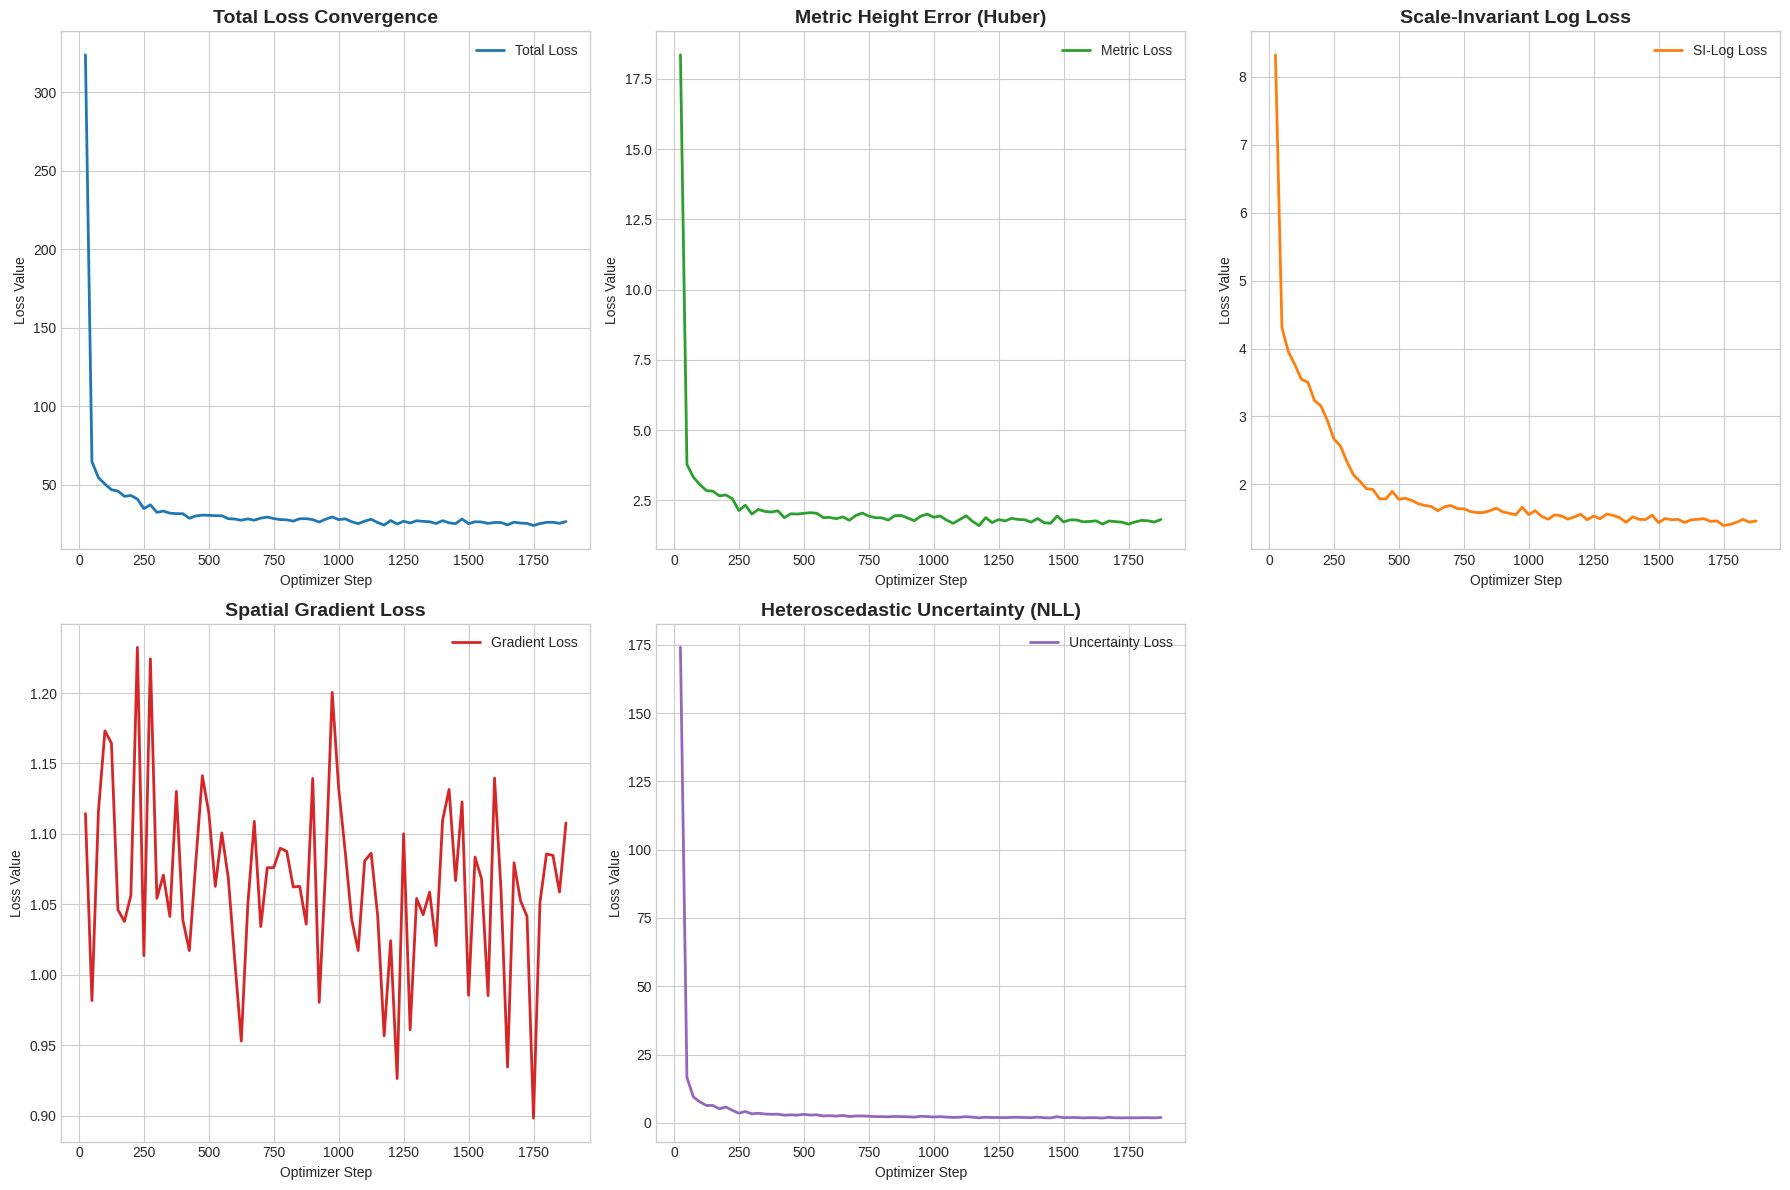

Loss plot saved to /kaggle/working/phase_a_training_losses.png


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# 1. Total Loss
plt.subplot(2, 3, 1)
plt.plot(history["step"], history["total_loss"], label="Total Loss", color="#1f77b4", linewidth=2)
plt.title("Total Loss Convergence", fontsize=14, fontweight="bold")
plt.xlabel("Optimizer Step")
plt.ylabel("Loss Value")
plt.legend()

# 2. Metric Huber Loss
plt.subplot(2, 3, 2)
plt.plot(history["step"], history["metric_loss"], label="Metric Loss", color="#2ca02c", linewidth=2)
plt.title("Metric Height Error (Huber)", fontsize=14, fontweight="bold")
plt.xlabel("Optimizer Step")
plt.ylabel("Loss Value")
plt.legend()

# 3. Scale-Invariant Log Loss
plt.subplot(2, 3, 3)
plt.plot(history["step"], history["si_loss"], label="SI-Log Loss", color="#ff7f0e", linewidth=2)
plt.title("Scale-Invariant Log Loss", fontsize=14, fontweight="bold")
plt.xlabel("Optimizer Step")
plt.ylabel("Loss Value")
plt.legend()

# 4. Gradient Loss
plt.subplot(2, 3, 4)
plt.plot(history["step"], history["grad_loss"], label="Gradient Loss", color="#d62728", linewidth=2)
plt.title("Spatial Gradient Loss", fontsize=14, fontweight="bold")
plt.xlabel("Optimizer Step")
plt.ylabel("Loss Value")
plt.legend()

# 5. Uncertainty Loss
plt.subplot(2, 3, 5)
plt.plot(history["step"], history["uncertainty_loss"], label="Uncertainty Loss", color="#9467bd", linewidth=2)
plt.title("Heteroscedastic Uncertainty (NLL)", fontsize=14, fontweight="bold")
plt.xlabel("Optimizer Step")
plt.ylabel("Loss Value")
plt.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/phase_a_training_losses.png", dpi=300, bbox_inches="tight")
plt.show()

print("Loss plot saved to /kaggle/working/phase_a_training_losses.png")

In [10]:
import numpy as np

model.eval()

val_mae_list = []
val_rmse_list = []
MAX_VAL_SAMPLES = 200 # Limit to 200 crops for quick validation; set to None to evaluate all

print(f"Beginning Phase A Validation (evaluating up to {MAX_VAL_SAMPLES} crops)...")

with torch.no_grad():
    for idx, batch in enumerate(val_loader, start=1):
        if MAX_VAL_SAMPLES is not None and idx > MAX_VAL_SAMPLES:
            break

        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            # Note: Ensure this key matches your model's forward output dictionary
            preds = outputs["metric_nDSM"]

        # Apply valid evaluation mask (matches loss function logic)
        mask = (valid_masks > 0.5) & torch.isfinite(targets) & (targets >= 0.0)
        if not mask.any():
            continue

        p_valid = preds[mask]
        t_valid = targets[mask]

        # 1. Mean Absolute Error (MAE)
        mae = torch.abs(p_valid - t_valid).mean().item()
        val_mae_list.append(mae)

        # 2. Root Mean Squared Error (RMSE)
        rmse = torch.sqrt(torch.mean((p_valid - t_valid) ** 2)).item()
        val_rmse_list.append(rmse)

        if idx % 50 == 0:
            current_mae = float(np.mean(val_mae_list)) if val_mae_list else 0.0
            print(f" Processed {idx} crops -> Current Avg MAE: {current_mae:.3f} m")

mean_mae = float(np.mean(val_mae_list)) if val_mae_list else 0.0
mean_rmse = float(np.mean(val_rmse_list)) if val_rmse_list else 0.0

print("\n" + "="*50)
print(" PHASE A FINAL BENCHMARK REPORT")
print("="*50)
print(f"Phase A Final MAE:  {mean_mae:.3f} m")
print(f"Phase A Final RMSE: {mean_rmse:.3f} m")
print("="*50)

if mean_mae < 3.5:
    print("Result: Excellent baseline! Ready for Phase B (Nadir Adaptation).")
elif mean_mae < 4.5:
    print("Result: Good baseline. Proceed to Phase B.")
else:
    print("Result: Baseline is high. Check data masking and affine head initialization.")

Beginning Phase A Validation (evaluating up to 200 crops)...
 Processed 50 crops -> Current Avg MAE: 2.332 m
 Processed 100 crops -> Current Avg MAE: 2.310 m
 Processed 150 crops -> Current Avg MAE: 2.273 m
 Processed 200 crops -> Current Avg MAE: 2.083 m

 PHASE A FINAL BENCHMARK REPORT
Phase A Final MAE:  2.083 m
Phase A Final RMSE: 3.372 m
Result: Excellent baseline! Ready for Phase B (Nadir Adaptation).
